## Exercise 3: Value Factor Backtest
Take an index universe (e.g. S&P 500 constituents or a French-library value sort). Rank by earnings yield or book-to-market each month, form a long-top-decile / short-bottom-decile portfolio, and backtest 10+ years. Report annualised return, volatility, Sharpe, max drawdown, and plot the value drawdown of 2018–2020. Comment on whether the premium survived in your sample.

### Report

For this exercise, we used a Kenneth French Data Library dataset containing returns of US stock portfolios grouped into deciles by their book to market ratio.

The strategy was designed to buy the 10% of stocks with the highest book to market ratios, and short  the 10% with the lowest ratios. This meant buying stocks of companies that were cheap relative to their accounting value and shorting stocks that were expensive relative to that value.

A 10 years strategy backtest, between Jan 2014 and Jan 2024, generated an annualised return of −8.9%, volatility of 21.04%, and a Sharpe ratio of -0.3375. This indicates that startegy on average lost money every year, while also experiencing substantial fluctuations. Therefore in this sample the value premium did not survive, as value stocks underperformed growth stocks over the period.

The value drawdown graph shows how far the strategy fell below it's previous peak during 2018-2020 period. The drawdown generally deepened from 2018 to September 2020, reaching a maximum value of 69.08%, despite some temporary recoveries. 



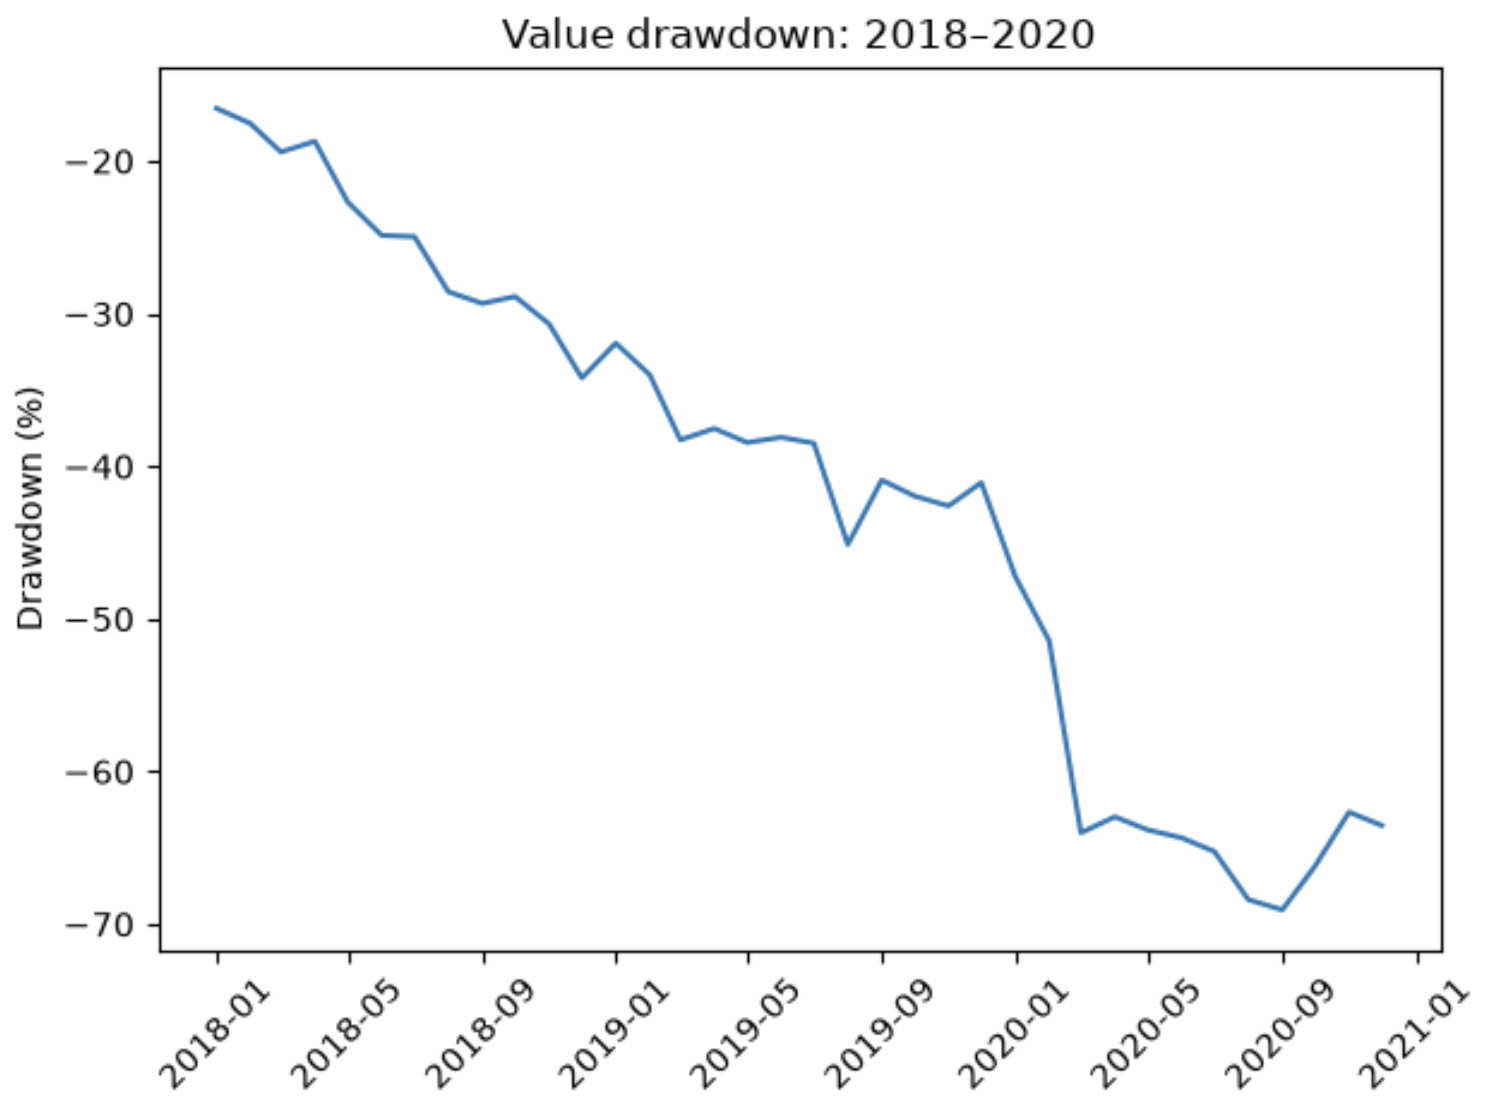





In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

full_data = pd.read_csv("./data/Portfolios_Formed_on_BE-ME.csv", sep = ";")

full_data = full_data.rename(columns = {"Unnamed: 0": "Month"})
full_data["Month"] = pd.to_datetime(full_data["Month"].astype(str), format = "%Y%m" )

# Lo 10 - 10% of stocks with the lowest book-to-market ratios -> short
# Hi 10 - 10% of stocks with the highest book-to-market ratios -> buy
data = full_data.loc[:, ["Month", "Lo 10", "Hi 10"]]

# Selecting 10 years
data = data.loc[data["Month"].between("2014-01-01", "2024-01-01")].sort_values("Month")

# Monthly simple returns
data["Return"] = (data["Hi 10"] - data["Lo 10"]) / 100

# Multiplier
data["Cumulative"] = (1 + data["Return"]).cumprod(axis=0)

# Measures
r = data["Return"]
annual_return = data["Cumulative"].iloc[-1] ** (12 / len(r)) - 1
annual_volatility = r.std() * (12 ** 0.5)
sharpe = (r.mean() / r.std()) * (12 ** 0.5)

print(f"Annualised return: {annual_return.round(4)}")
print(f"Annualised volatility: {annual_volatility.round(4)}")
print(f"Sharpe ratio: {sharpe.round(4)}")

# Drawdown
peak = data["Cumulative"].cummax().clip(lower=1)
data["Drawdown"] = data["Cumulative"] / peak - 1

print(f"Maximum drawdown: {data['Drawdown'].min().round(2)}")

# Plot 2018–2020
plot_data = data[data["Month"].between("2018-01-01", "2020-12-31")]

plt.plot(plot_data["Month"], plot_data["Drawdown"] * 100)
plt.title("Value drawdown: 2018–2020")
plt.ylabel("Drawdown (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()